In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
GRID = False
FONT_SIZE = 18
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

# Surface Tracking: Energy Consumption

Two stiffnesses tracking the same slanted-obstacle reference: k = 8 N/m (soft) vs
k = 70 N/m (stiff). Energy is the actuators' total mechanical work — |tau · qdot|
summed over all 9 motors and integrated over the first 45 s — in joules.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.integrate import trapezoid as trapz

# Soft vs stiff comparison
k_values = [8, 70]
data = {}

for k in k_values:
    fname = os.path.join('outputs', 'surface_tracking', f'k{k}.npz')
    d = np.load(fname)
    data[k] = d
    print(f"Loaded {fname}: {len(d['t'])} samples")

Loaded outputs\surface_tracking\k8.npz: 24719 samples
Loaded outputs\surface_tracking\k70.npz: 20399 samples


k=8: Energy (0-45s) = 0.22 J
k=70: Energy (0-45s) = 0.43 J


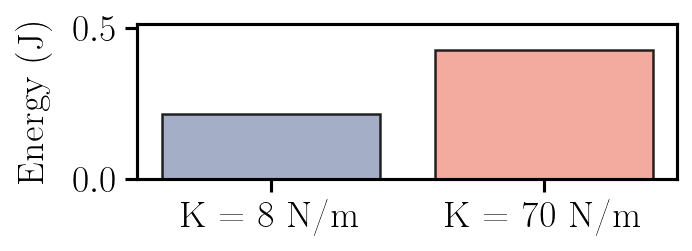


Energy ratio (stiff/soft): 1.98x


In [3]:
# Figure aspect ratio (width:height), as a ratio of two integers -- TUNE THIS.
ASPECT_W, ASPECT_H = 13, 4.5

YLABEL_PAD = 10  # pt -- TUNE THIS: space between 'Energy (J)' and the axis/tick numbers

# Energy: total |tau . qdot| (mechanical work, in joules), soft vs stiff, over the first 45 s
k_compare      = [8, 70]
colors_compare = [COLORS[3], COLORS[1]]
k_display      = {8: 8, 70: 70}
value_labels   = [f'K = {k_display[k]} N/m' for k in k_compare]

energy_values = {}

for k in k_compare:
    d    = data[k]
    t    = d['t'] - d['t'][0]
    tau  = d['tau']          # (n, 9) [N.m]
    qdot = d['q_motor_dot']  # (n, 9) [rad/s]

    idx_45s  = np.searchsorted(t, 45.0)
    t_window = t[:idx_45s]
    # per-motor mechanical power |tau * qdot| [W], summed across all 9 motors,
    # integrated over time -> total actuator work [J]
    power  = np.sum(np.abs(tau[:idx_45s] * qdot[:idx_45s]), axis=1)
    energy = trapz(power, t_window)
    energy_values[k] = energy
    print(f"k={k}: Energy (0-45s) = {energy:.2f} J")

FIG_W = FIG_W_SINGLE * 1.3
FIG_H = FIG_W * ASPECT_H / ASPECT_W
fig, ax_energy = plt.subplots(figsize=(FIG_W, FIG_H), layout='constrained')

ax_energy.bar(range(len(k_compare)), [energy_values[k] for k in k_compare],
              color=colors_compare, alpha=0.85, edgecolor='black', linewidth=1.2)
ax_energy.set_xticks(range(len(k_compare)))
ax_energy.set_xticklabels(value_labels)
ax_energy.set_ylabel('Energy (J)', labelpad=YLABEL_PAD)
ax_energy.grid(GRID, axis='y')

# No per-bar value labels (numbers are printed above instead), but keep the
# same headroom as before (*1.2, not the tighter *1.05) -- it's what put the
# 0.5 gridline at the top, which read better.
max_energy = max(energy_values.values())
ax_energy.set_ylim(0, max_energy * 1.2)

fig.savefig(os.path.join('outputs', 'surface_tracking', 'energy_comparison.pdf'))
plt.show()

print(f"\nEnergy ratio (stiff/soft): {energy_values[70] / energy_values[8]:.2f}x")

## Marker Tracking: X and Y Position

Tip-marker trajectory from video tracking (Kinovea export, `k{K}.xlsx`) for the soft
and stiff runs. X and Y each get their own figure, with both stiffnesses overlaid.

Loaded outputs\surface_tracking\k8.xlsx: 1091 samples, 36.3 s
Loaded outputs\surface_tracking\k70.xlsx: 860 samples, 28.6 s


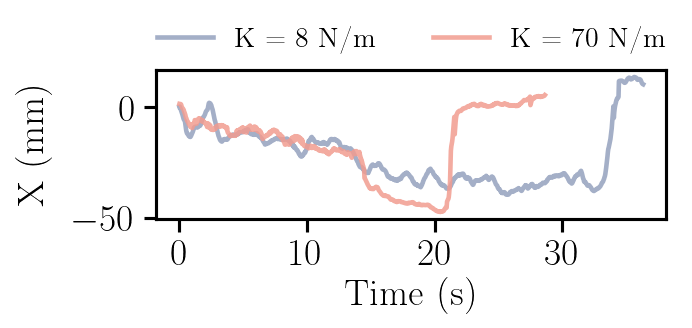

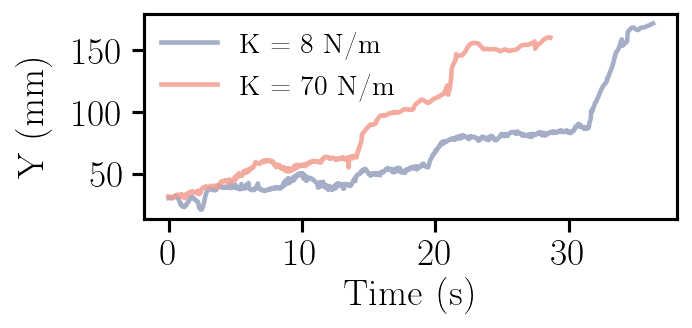

In [4]:
import zipfile
import xml.etree.ElementTree as ET

# Figure aspect ratio (width:height) for the X and Y plots -- TUNE THIS.
TRACK_ASPECT_W, TRACK_ASPECT_H = 13, 6
TRACK_LINEWIDTH = 2.2
# Per-figure legend placement -- TUNE THIS. X has no empty corner, so its
# legend sits above the axes in one row; Y's upper-left corner is free.
TRACK_LEGEND_KW = {
    'X': dict(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False),
    'Y': dict(loc='upper left', framealpha=0.9),
}


def load_kinovea_xlsx(fname):
    """Read the trajectory table (Time (s), X (mm), Y (mm)) from a Kinovea .xlsx
    export. Parsed with the stdlib so no pandas/openpyxl is needed. The
    trajectory is the block under the first row whose first cell is 'Time (s)'
    (the earlier 'Name | Time (s) | ...' rows are summary tables). Kinovea
    writes the same trajectory twice ('Marker 1.0' and 'Marker 1'), so reading
    stops at the next non-numeric row."""
    ns = {'x': 'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
    with zipfile.ZipFile(fname) as z:
        strings = [si.findtext('.//x:t', namespaces=ns)
                   for si in ET.fromstring(z.read('xl/sharedStrings.xml')).findall('x:si', ns)]
        sheet = ET.fromstring(z.read('xl/worksheets/sheet1.xml'))

    rows = []
    for r in sheet.iter(f'{{{ns["x"]}}}row'):
        vals = []
        for c in r.findall('x:c', ns):
            v = c.findtext('x:v', namespaces=ns)
            if v is not None and c.get('t') == 's':
                v = strings[int(v)]
            vals.append(v)
        rows.append(vals)

    start = next(i for i, r in enumerate(rows) if r and r[0] == 'Time (s)') + 1
    samples = []
    for r in rows[start:]:
        try:
            samples.append([float(v) for v in r[:3]])
        except (TypeError, ValueError):
            break
    arr = np.array(samples)
    return arr[:, 0], arr[:, 1], arr[:, 2]


track = {}
for k in k_compare:
    fname = os.path.join('outputs', 'surface_tracking', f'k{k}.xlsx')
    t_k, x_k, y_k = load_kinovea_xlsx(fname)
    track[k] = (t_k - t_k[0], x_k, y_k)
    print(f"Loaded {fname}: {len(t_k)} samples, {t_k[-1] - t_k[0]:.1f} s")

FIG_W_TRACK = FIG_W_SINGLE * 1.3
FIG_H_TRACK = FIG_W_TRACK * TRACK_ASPECT_H / TRACK_ASPECT_W

for col, axis_name in [(1, 'X'), (2, 'Y')]:
    fig, ax = plt.subplots(figsize=(FIG_W_TRACK, FIG_H_TRACK), layout='constrained')
    for k, color, label in zip(k_compare, colors_compare, value_labels):
        ax.plot(track[k][0], track[k][col], color=color, linewidth=TRACK_LINEWIDTH,
                alpha=0.85, label=label)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel(f'{axis_name} (mm)', labelpad=YLABEL_PAD)
    ax.grid(GRID)
    ax.legend(**TRACK_LEGEND_KW[axis_name])
    fig.savefig(os.path.join('outputs', 'surface_tracking', f'tracking_{axis_name.lower()}.pdf'))
    fig.savefig(os.path.join('outputs', 'surface_tracking', f'tracking_{axis_name.lower()}.png'), dpi=300)
    plt.show()

## Marker Tracking: XY Trajectory (corrected data)

Y vs X trajectory from the hand-corrected `k_compare.xlsx` (one sheet with a
`Time (s) | X_K{K} | Y_K{K}` column block per stiffness), both stiffnesses overlaid
and coloured by time. The X/Y-vs-time plots above use the raw Kinovea exports.

In [5]:
import re
import zipfile
import xml.etree.ElementTree as ET


def load_xlsx_columns(fname):
    """Read the first sheet of an .xlsx into {header: np.array} (stdlib only, no
    pandas/openpyxl). Headers come from row 1; each column is read down until
    its first empty cell, so columns of different lengths are fine. Repeated
    headers (e.g. one 'Time (s)' per block) are keyed by the header of the
    column to their right instead, e.g. 'Time (s)|X_K8'."""
    ns = {'x': 'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
    with zipfile.ZipFile(fname) as z:
        strings = [''.join(t.text or '' for t in si.iter(f'{{{ns["x"]}}}t'))
                   for si in ET.fromstring(z.read('xl/sharedStrings.xml')).findall('x:si', ns)]
        sheet = ET.fromstring(z.read('xl/worksheets/sheet1.xml'))

    cells = {}  # (col letters, row number) -> value
    for c in sheet.iter(f'{{{ns["x"]}}}c'):
        v = c.findtext('x:v', namespaces=ns)
        if v is None:
            continue
        col, row = re.fullmatch(r'([A-Z]+)(\d+)', c.get('r')).groups()
        cells[(col, int(row))] = strings[int(v)] if c.get('t') == 's' else float(v)

    col_index = lambda col: sum((ord(ch) - 64) * 26 ** i for i, ch in enumerate(reversed(col)))
    header_cols = sorted((col for col, row in cells if row == 1), key=col_index)
    headers = {col: cells[(col, 1)] for col in header_cols}

    out = {}
    for col in header_cols:
        vals = []
        row = 2
        while (col, row) in cells:
            vals.append(cells[(col, row)])
            row += 1
        name = headers[col]
        if list(headers.values()).count(name) > 1:
            right = next(c for c in header_cols if col_index(c) == col_index(col) + 1)
            name = f'{name}|{headers[right]}'
        out[name] = np.array(vals, dtype=float)
    return out


cols = load_xlsx_columns(os.path.join('outputs', 'surface_tracking', 'k_compare.xlsx'))

track_cmp = {}
for k in k_compare:
    t_k = cols[f'Time (s)|X_K{k}']
    x_k, y_k = cols[f'X_K{k}'], cols[f'Y_K{k}']
    n = min(len(t_k), len(x_k), len(y_k))
    track_cmp[k] = (t_k[:n] - t_k[0], x_k[:n], y_k[:n])
    print(f"k={k}: {n} samples, {t_k[n - 1] - t_k[0]:.1f} s")

k=8: 956 samples, 31.8 s
k=70: 860 samples, 28.6 s


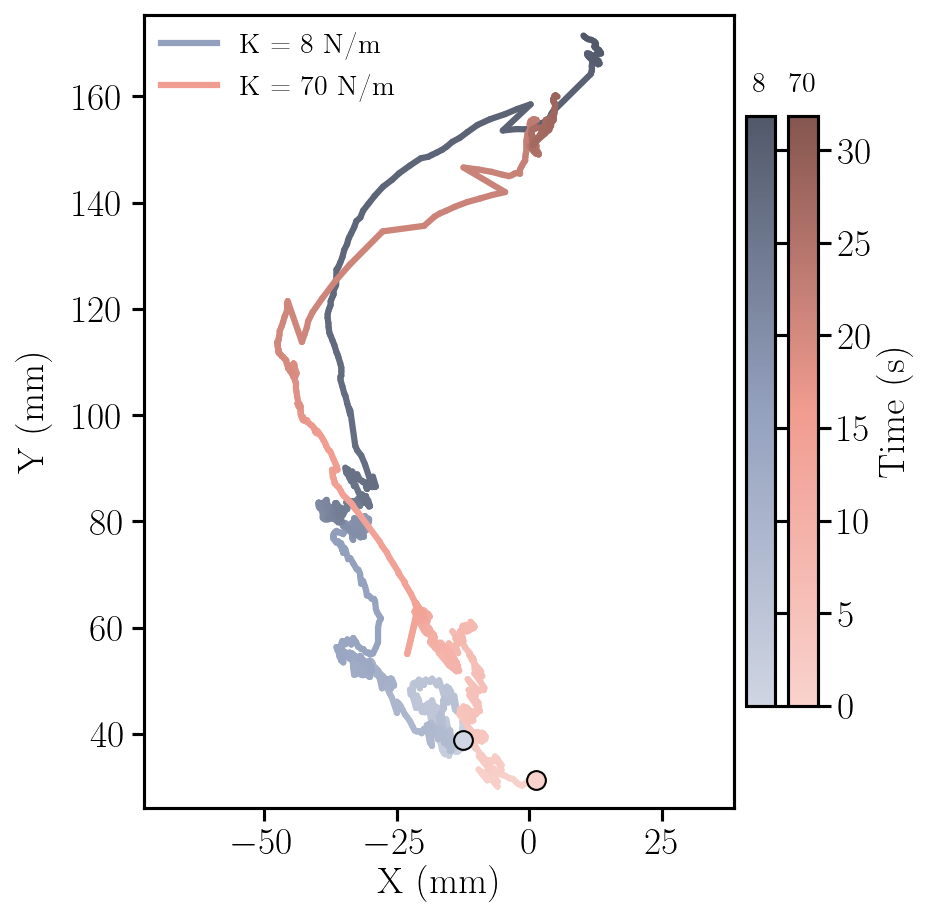

In [6]:
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgb
from matplotlib.lines import Line2D

# XY trajectory (corrected data): Y vs X for both stiffnesses, equal axis
# scaling so the path shape isn't distorted. Colour encodes time: each run
# keeps its usual hue (colors_compare, as in the plots above) and goes light
# (start) -> dark (end), on one shared time scale. Circle = start.
XY_FIG_H     = 6.0   # inches -- TUNE THIS; width follows from the data's aspect ratio
XY_LINEWIDTH = 3.0
XY_LIGHT     = 0.55  # start-of-run tint: fraction mixed with white -- TUNE THIS
XY_DARK      = 0.45  # end-of-run shade: fraction mixed with black -- TUNE THIS
XY_LEGEND_KW = dict(loc='upper left', framealpha=0.9)  # TUNE THIS


def time_cmap(color):
    c = np.array(to_rgb(color))
    return LinearSegmentedColormap.from_list(
        f'time_{color}', [c + (1 - c) * XY_LIGHT, c, c * (1 - XY_DARK)])


xy_cmaps = {k: time_cmap(color) for k, color in zip(k_compare, colors_compare)}

x_all = np.concatenate([track_cmp[k][1] for k in k_compare])
y_all = np.concatenate([track_cmp[k][2] for k in k_compare])
xy_aspect = (x_all.max() - x_all.min()) / (y_all.max() - y_all.min())
norm = Normalize(vmin=0, vmax=max(track_cmp[k][0][-1] for k in k_compare))

fig, ax = plt.subplots(figsize=(XY_FIG_H * xy_aspect + 3.5, XY_FIG_H), layout='constrained')
legend_handles = []
for k, label in zip(k_compare, value_labels):
    t_k, x_k, y_k = track_cmp[k]
    cmap = xy_cmaps[k]
    pts  = np.column_stack([x_k, y_k]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    lc = LineCollection(segs, cmap=cmap, norm=norm, linewidth=XY_LINEWIDTH,
                        capstyle='round', joinstyle='round', zorder=3)
    lc.set_array(0.5 * (t_k[:-1] + t_k[1:]))
    ax.add_collection(lc)
    ax.plot(x_k[0], y_k[0], 'o', color=cmap(0.0), markersize=9, markeredgecolor='black', zorder=4)
    legend_handles.append(Line2D([], [], color=cmap(0.5), linewidth=XY_LINEWIDTH, label=label))

ax.autoscale_view()
ax.set_aspect('equal', adjustable='datalim')
ax.set_xlabel('X (mm)')
ax.set_ylabel('Y (mm)', labelpad=YLABEL_PAD)
ax.grid(GRID)
ax.legend(handles=legend_handles, **XY_LEGEND_KW)

# One colorbar per stiffness (same time scale), titled with its K. constrained
# layout puts each new colorbar *between* the axes and the previous ones, so
# they're added outermost-first; only the outermost carries tick numbers and
# the 'Time (s)' label.
for i, k in enumerate(reversed(k_compare)):
    sm = plt.cm.ScalarMappable(cmap=xy_cmaps[k], norm=norm)
    cbar = fig.colorbar(sm, ax=ax, fraction=0.05, pad=0.02)
    cbar.ax.set_title(f'{k}', fontsize=LEGEND_FONT_SIZE)
    if i == 0:
        cbar.set_label('Time (s)')
    else:
        cbar.ax.tick_params(labelright=False)

fig.savefig(os.path.join('outputs', 'surface_tracking', 'k_compare_xy.pdf'))
fig.savefig(os.path.join('outputs', 'surface_tracking', 'k_compare_xy.png'), dpi=300)
plt.show()